# Practical 9 — Graph Neural Networks on Protein Graphs

**Machine Learning for Bioinformatics**

## Main question

\[
\boxed{\text{Can we classify proteins from graph structure and node features?}}
\]

Dataset: **PROTEINS** from the TU graph benchmark collection via PyTorch Geometric.

Workflow:

\[
\text{graph inspection}
\rightarrow
\text{graph-statistics baseline}
\rightarrow
\text{GCN}
\rightarrow
\text{GIN}
\rightarrow
\text{graph embeddings}
\rightarrow
\text{transfer learning}
\rightarrow
\text{knowledge distillation}
\]

## Learning objectives

By the end of the practical, students should be able to:

- inspect `Data(x, edge_index, y)`;
- understand graph mini-batching and the `batch` vector;
- build a classical baseline from graph statistics;
- train a graph-level GCN classifier;
- compare GCN and GIN;
- extract graph embeddings;
- reuse a pretrained graph encoder with frozen and fine-tuned transfer;
- distinguish transfer learning from knowledge distillation.

# Part 0 — Environment

In [1]:
# If needed:
# pip install torch torch-geometric scikit-learn networkx matplotlib pandas

import time, copy, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch_geometric.datasets import TUDataset
from torch_geometric.loader import DataLoader
from torch_geometric.nn import (
    GCNConv, GINConv, SAGEConv, GATConv,
    global_mean_pool, global_add_pool, global_max_pool
)
from torch_geometric.utils import to_networkx

RANDOM_STATE = 41126
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__)
print("Device:", DEVICE)

# Shared model widths used throughout the practical.
BASELINE_GCN_HIDDEN = 128
STUDENT_GCN_HIDDEN = 64
GIN_HIDDEN_DIM = 128
TEACHER_GIN_HIDDEN = 256
print({
    "baseline_gcn_hidden": BASELINE_GCN_HIDDEN,
    "student_gcn_hidden": STUDENT_GCN_HIDDEN,
    "teacher_gin_hidden": TEACHER_GIN_HIDDEN,
})

PyTorch: 2.11.0+cu128
Device: cuda
{'baseline_gcn_hidden': 128, 'student_gcn_hidden': 64, 'teacher_gin_hidden': 256}


# Part I — Load and inspect PROTEINS

## What is the PROTEINS dataset?

`PROTEINS` is a **graph-level protein classification** benchmark from the TU Dortmund graph-kernel collection. Each graph represents one protein structure. The dataset contains **1,113 protein graphs** and the task has **two classes**.

In the standard release, the classes are:

- **non-enzyme**: 663 protein graphs;
- **enzyme**: 450 protein graphs.

The class is attached to the **whole graph**, not to an individual node. It answers a binary question: *does this protein belong to the enzyme or non-enzyme group?* It does **not** specify which biochemical reaction an enzyme catalyses. In particular, these are not the six enzyme classes from the separate `ENZYMES` dataset.

## What does one graph contain?

### Nodes

A node represents a **secondary-structure element (SSE)** of a protein rather than a single amino acid. The three node-label categories describe the local secondary structure: helix, sheet, or turn. With the default `TUDataset(..., use_node_attr=False)` setting used here, PyG represents these categories as three node features, effectively a one-hot vector.

The raw release also contains an optional continuous node-attribute file. We do not use those attributes in this practical, so the model starts from the categorical SSE information only.

### Edges

Edges describe structural or sequential neighbourhood relationships used to construct the protein graph. They connect nearby secondary-structure elements along the protein sequence and/or in the three-dimensional structure. `edge_index` stores the sparse connectivity; for an undirected graph, both directions can be stored.

### Graph label

`y` contains one target per protein graph. PyG remaps the raw labels to zero-based integers, so this notebook uses:

```text
0 → non-enzyme
1 → enzyme
```

This is a **graph classification** problem: the number of nodes and edges can differ between proteins, but every graph receives one label.

## What is not available here?

The benchmark files do not provide protein names, amino-acid sequences, UniProt IDs, PDB IDs, or the original 3D coordinates. We therefore study how much can be learned from the compact graph representation: secondary-structure node labels plus graph connectivity.

Useful references: [PyG's TUDataset documentation](https://pytorch-geometric.readthedocs.io/en/stable/generated/torch_geometric.datasets.TUDataset.html) and the original protein-function graph-kernel paper, [Borgwardt et al. (2005)](https://doi.org/10.1093/bioinformatics/bti1007).


In [2]:
dataset = TUDataset(root="data/TUDataset", name="PROTEINS")

print(dataset)
print("Number of graphs:", len(dataset))
print("Node features:", dataset.num_node_features)
print("Classes:", dataset.num_classes)

data = dataset[0]
print(data)
print("x:", data.x.shape)
print("edge_index:", data.edge_index.shape)
print("y:", data.y)
print("nodes:", data.num_nodes, "edges:", data.num_edges)

PROTEINS(1113)
Number of graphs: 1113
Node features: 3
Classes: 2
Data(edge_index=[2, 162], x=[42, 3], y=[1])
x: torch.Size([42, 3])
edge_index: torch.Size([2, 162])
y: tensor([0])
nodes: 42 edges: 162


For a graph with \(N\) nodes and \(d\) features:

\[
X \in \mathbb{R}^{N\times d}
\]

and sparse connectivity is stored as:

\[
edge\_index \in \mathbb{N}^{2\times E}
\]

Questions:
- Why does `x.shape[0]` differ between graphs?
- Why is `y` stored once per graph?
- Why can an undirected edge appear twice in `edge_index`?

# Part II — Explore graph sizes and labels


Class mapping: {0: 'non-enzyme', 1: 'enzyme'}
Dataset properties
Graphs: 1113
Classes: 2
Node features per node: 3
Total nodes: 43471
Total stored edges: 162088
Class proportions:


,proportion
class_name,
non-enzyme,0.595687
enzyme,0.404313


,graph_id,label,num_nodes,num_edges,class_name,label_category
count,1113.00000,1113.000000,1113.000000,1113.000000,1113,1113
unique,NaN,NaN,NaN,NaN,2,2
top,NaN,NaN,NaN,NaN,non-enzyme,class_0
freq,NaN,NaN,NaN,NaN,663,663
mean,556.00000,0.404313,39.057502,145.631626,NaN,NaN
std,321.43973,0.490979,45.778992,169.274151,NaN,NaN
min,0.00000,0.000000,4.000000,10.000000,NaN,NaN
25%,278.00000,0.000000,15.000000,56.000000,NaN,NaN
50%,556.00000,0.000000,26.000000,98.000000,NaN,NaN
75%,834.00000,1.000000,45.000000,174.000000,NaN,NaN


Node-feature matrix: (43471, 3)
Node-feature range: 0.0 to 1.0
Zero fraction: 0.667


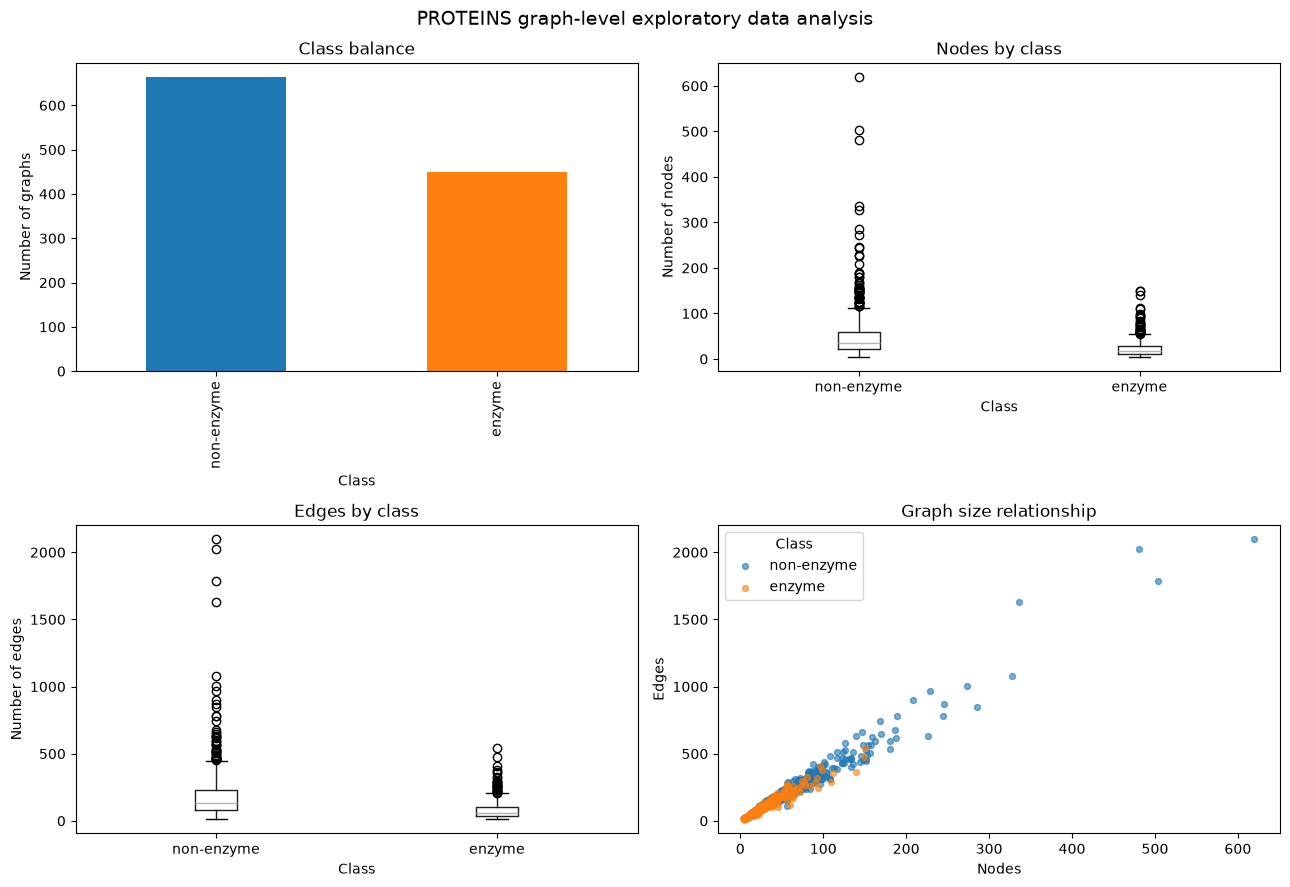

In [3]:
records = []
for i, g in enumerate(dataset):
    records.append({
        "graph_id": i,
        "label": int(g.y.item()),
        "num_nodes": g.num_nodes,
        "num_edges": g.num_edges
    })

graph_df = pd.DataFrame(records)
CLASS_NAMES = {0: "non-enzyme", 1: "enzyme"}
graph_df["class_name"] = pd.Categorical(
    graph_df["label"].map(CLASS_NAMES),
    categories=["non-enzyme", "enzyme"]
)
assert graph_df["class_name"].notna().all(), "Unexpected class label found"
graph_df["label_category"] = pd.Categorical(
    graph_df["label"].map(lambda value: f"class_{value}"),
    categories=[f"class_{value}" for value in sorted(graph_df["label"].unique())]
)
print("Class mapping:", CLASS_NAMES)

print("Dataset properties")
print("Graphs:", len(dataset))
print("Classes:", dataset.num_classes)
print("Node features per node:", dataset.num_node_features)
print("Total nodes:", int(graph_df["num_nodes"].sum()))
print("Total stored edges:", int(graph_df["num_edges"].sum()))
print("Class proportions:")
display(graph_df["class_name"].value_counts(normalize=True).sort_index().rename("proportion").to_frame())
display(graph_df.describe(include="all"))

# Concatenate node features to inspect their range and sparsity.
all_node_features = torch.cat([g.x for g in dataset], dim=0).numpy()
print("Node-feature matrix:", all_node_features.shape)
print("Node-feature range:", float(all_node_features.min()), "to", float(all_node_features.max()))
print("Zero fraction:", round(float((all_node_features == 0).mean()), 3))

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
graph_df["class_name"].value_counts().sort_index().plot.bar(ax=axes[0, 0], color=["tab:blue", "tab:orange"])
axes[0, 0].set(title="Class balance", xlabel="Class", ylabel="Number of graphs")
graph_df.boxplot(column="num_nodes", by="class_name", ax=axes[0, 1], grid=False)
axes[0, 1].set(title="Nodes by class", xlabel="Class", ylabel="Number of nodes")
graph_df.boxplot(column="num_edges", by="class_name", ax=axes[1, 0], grid=False)
axes[1, 0].set(title="Edges by class", xlabel="Class", ylabel="Number of edges")
for category, group in graph_df.groupby("class_name", observed=True):
    axes[1, 1].scatter(group["num_nodes"], group["num_edges"], s=18, alpha=0.6, label=category)
axes[1, 1].set(title="Graph size relationship", xlabel="Nodes", ylabel="Edges")
axes[1, 1].legend(title="Class")
fig.suptitle("PROTEINS graph-level exploratory data analysis", fontsize=14)
plt.tight_layout()
plt.show()

### Discussion

Could graph size itself be predictive?  
If so, a GNN may partly exploit a shortcut rather than subtle graph structure.

# Part III — Visualize graphs


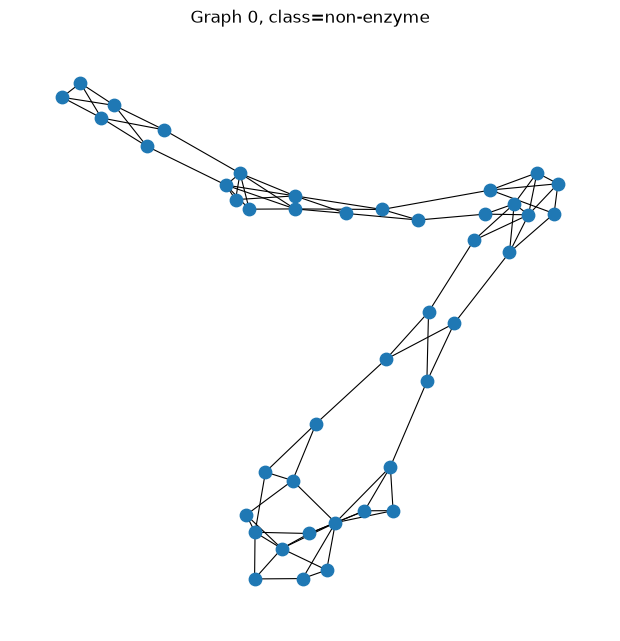

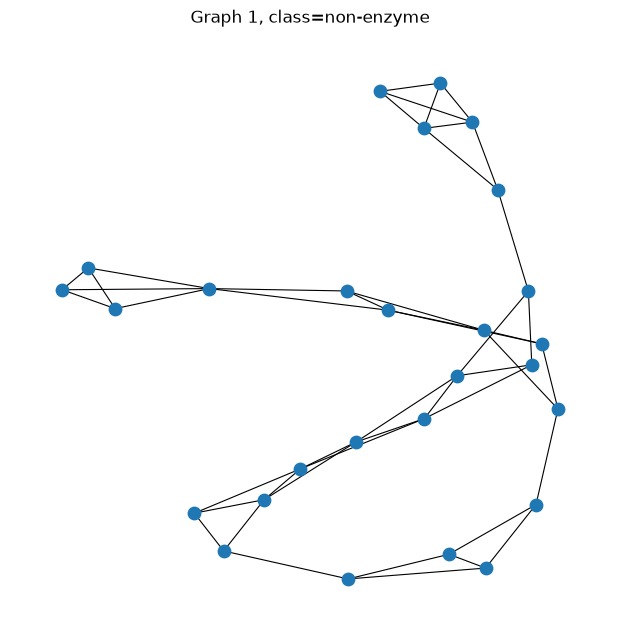

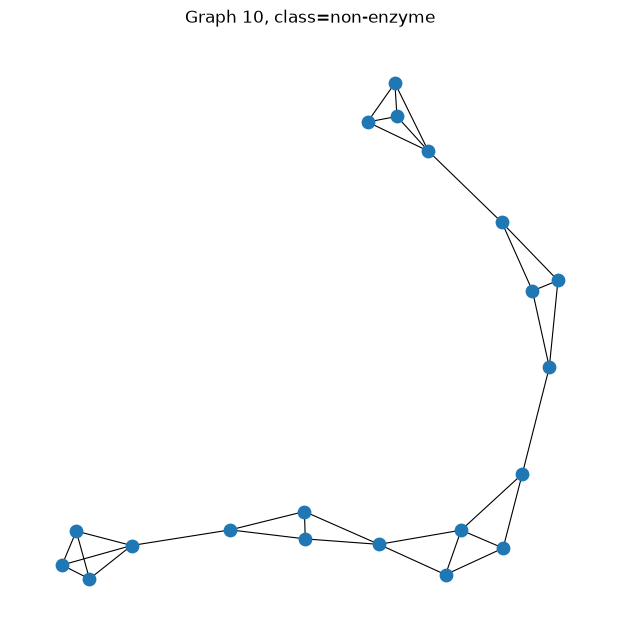

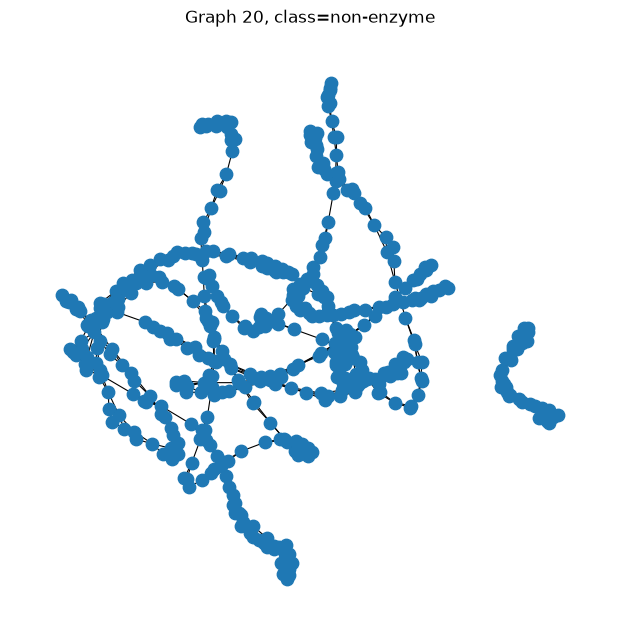

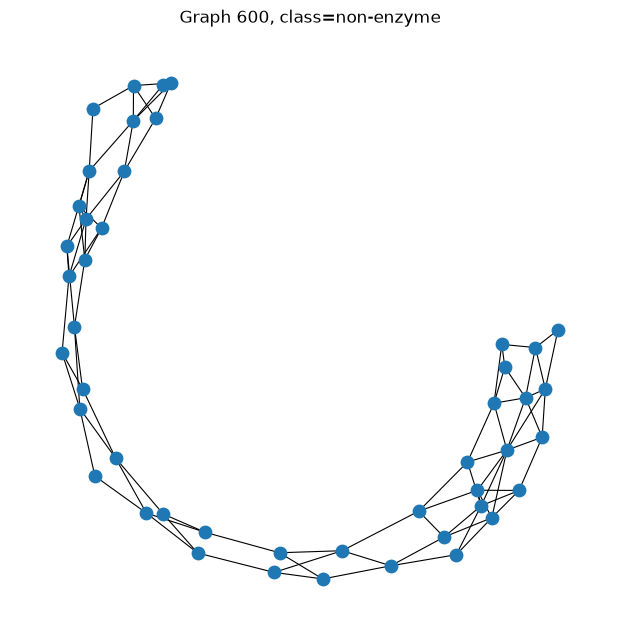

In [4]:
def plot_graph(data, title=None):
    G = to_networkx(data, to_undirected=True)
    plt.figure(figsize=(6,6))
    pos = nx.spring_layout(G, seed=RANDOM_STATE)
    nx.draw(G, pos, node_size=80, width=0.8, with_labels=False)
    if title:
        plt.title(title)
    plt.show()

# Display examples from both graph classes. The node positions are for visualization only;
# the GNN receives the original edge_index representation.
for idx in [0, 1, 10, 20, 600]:
    plot_graph(dataset[idx], f"Graph {idx}, class={CLASS_NAMES[int(dataset[idx].y.item())]}")

## Inspect the contents of one graph

The graph-level label is only one value, but the graph itself contains several variable-sized objects:

- `x`: one feature vector for every node;
- `edge_index`: a sparse \(2 \\times E\) table storing source and target node indices;
- `y`: one class label for the complete graph;
- no edge attributes are used in this practical.

The next cell exposes the first graph as ordinary tables. This is useful for checking what a GNN actually receives before discussing message passing.


In [5]:
graph_index = 0
one_graph = dataset[graph_index]

print("Graph label:", int(one_graph.y.item()), "→", CLASS_NAMES[int(one_graph.y.item())])
print("Number of nodes:", one_graph.num_nodes)
print("Stored edge rows:", one_graph.edge_index.shape[1])
print("Node-feature shape:", tuple(one_graph.x.shape))
print("Edge attributes:", getattr(one_graph, "edge_attr", None))

# A node table: one row per node and one column per input feature.
node_features = one_graph.x.cpu().numpy()
node_table = pd.DataFrame(
    node_features,
    columns=[f"x_{j}" for j in range(node_features.shape[1])]
)
node_table.insert(0, "node_id", np.arange(one_graph.num_nodes))
node_table["degree"] = np.bincount(
    one_graph.edge_index[0].cpu().numpy(), minlength=one_graph.num_nodes
)
display(node_table.head(12))

# edge_index is stored as two rows: source node and target node.
edge_array = one_graph.edge_index.t().cpu().numpy()
edge_table = pd.DataFrame(edge_array, columns=["source", "target"])
edge_table["source_degree"] = edge_table["source"].map(node_table.set_index("node_id")["degree"])
edge_table["target_degree"] = edge_table["target"].map(node_table.set_index("node_id")["degree"])
display(edge_table.head(20))

# For an undirected graph, opposite directions represent one relationship.
undirected_pairs = sorted({tuple(sorted((int(source), int(target)))) for source, target in edge_array})
print("Unique undirected relationships:", len(undirected_pairs))
display(pd.DataFrame(undirected_pairs, columns=["node_a", "node_b"]).head(20))


Graph label: 0 → non-enzyme
Number of nodes: 42
Stored edge rows: 162
Node-feature shape: (42, 3)
Edge attributes: None


,node_id,x_0,x_1,x_2,degree
0,0,1.0,0.0,0.0,3
1,1,1.0,0.0,0.0,3
2,2,1.0,0.0,0.0,3
3,3,1.0,0.0,0.0,5
4,4,1.0,0.0,0.0,6
5,5,1.0,0.0,0.0,3
6,6,1.0,0.0,0.0,3
7,7,1.0,0.0,0.0,4
8,8,1.0,0.0,0.0,5
9,9,1.0,0.0,0.0,6


,source,target,source_degree,target_degree
0,0,11,3,3
1,0,22,3,4
2,0,32,3,4
3,1,23,3,5
4,1,31,3,6
5,1,41,3,6
6,2,24,3,3
7,2,29,3,3
8,2,34,3,4
9,3,4,5,6


Unique undirected relationships: 81


,node_a,node_b
0,0,11
1,0,22
2,0,32
3,1,23
4,1,31
5,1,41
6,2,24
7,2,29
8,2,34
9,3,4


# Part IV — Reproducible split


In [6]:
indices = np.arange(len(dataset))
labels = np.array([int(g.y.item()) for g in dataset])

train_idx, temp_idx = train_test_split(
    indices, test_size=0.30, stratify=labels, random_state=RANDOM_STATE
)
val_idx, test_idx = train_test_split(
    temp_idx, test_size=0.50, stratify=labels[temp_idx], random_state=RANDOM_STATE
)

train_dataset = dataset[torch.tensor(train_idx)]
val_dataset   = dataset[torch.tensor(val_idx)]
test_dataset  = dataset[torch.tensor(test_idx)]

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
val_loader   = DataLoader(val_dataset, batch_size=128, shuffle=False)
test_loader  = DataLoader(test_dataset, batch_size=128, shuffle=False)

print(len(train_dataset), len(val_dataset), len(test_dataset))

779 167 167


# Part V — Classical graph-statistics baseline

## Why begin with graph statistics?

Before training a GNN, we create a deliberately simple baseline. Instead of passing the complete graph to a neural network, we summarise each graph (G) with a fixed-length vector of interpretable measurements:

\[
x_G = [N, E, \overline{d}, d_{\max}, \rho, C, K],
\]

where:

- (N) is the number of nodes;
- (E) is the number of undirected edges;
- (\overline{d} = 2E/N) is the mean node degree;
- (d_{\max}) is the largest node degree;
- (\rho = 2E/[N(N-1)]) is graph density;
- (C) is the average local clustering coefficient;
- (K) is the number of connected components.

This gives every protein the same number of columns, so ordinary tabular models such as logistic regression and random forest can be used.

The baseline is useful for three reasons:

1. **Sanity check:** it tells us whether the task is learnable from very coarse structure alone.
2. **Interpretability:** we can inspect whether graph size, density, or local connectivity differs between enzyme and non-enzyme proteins.
3. **Shortcut detection:** if graph statistics already perform well, a GNN may partly rely on graph-size or density differences rather than learning subtle structural patterns.

The compression is also a limitation. Two very different graphs can have the same (N), (E), and degree summaries. These statistics discard node identities, the arrangement of motifs, and the precise neighbourhood structure. A GNN is introduced later to retain and learn from that information.


In [7]:
def graph_statistics(data):
    G = to_networkx(data, to_undirected=True)
    n = G.number_of_nodes()
    e = G.number_of_edges()
    deg = [d for _, d in G.degree()]
    return [
        n,
        e,
        np.mean(deg) if deg else 0,
        np.max(deg) if deg else 0,
        nx.density(G),
        nx.average_clustering(G) if n > 1 else 0,
        nx.number_connected_components(G)
    ]

X_stats = np.array([graph_statistics(g) for g in dataset])
feature_names = ["num_nodes","num_edges","mean_degree","max_degree","density","clustering","components"]

stats_df = pd.DataFrame(X_stats, columns=feature_names)
stats_df["label"] = labels
display(stats_df.head())

,num_nodes,num_edges,mean_degree,max_degree,density,clustering,components,label
0,42.0,81.0,3.857143,8.0,0.094077,0.341667,1.0,0
1,27.0,46.0,3.407407,5.0,0.131054,0.601235,1.0,0
2,10.0,17.0,3.400000,5.0,0.377778,0.766667,1.0,0
3,24.0,46.0,3.833333,7.0,0.166667,0.267460,1.0,0
4,11.0,21.0,3.818182,5.0,0.381818,0.766667,1.0,0


In [8]:
baseline_lr = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=2000, class_weight="balanced"))
])
baseline_lr.fit(X_stats[train_idx], labels[train_idx])
pred = baseline_lr.predict(X_stats[val_idx])
print(classification_report(labels[val_idx], pred, digits=3))

baseline_rf = RandomForestClassifier(
    n_estimators=300, random_state=RANDOM_STATE, class_weight="balanced"
)
baseline_rf.fit(X_stats[train_idx], labels[train_idx])
pred_rf = baseline_rf.predict(X_stats[val_idx])
print(classification_report(labels[val_idx], pred_rf, digits=3))

              precision    recall  f1-score   support

           0      0.780     0.780     0.780       100
           1      0.672     0.672     0.672        67

    accuracy                          0.737       167
   macro avg      0.726     0.726     0.726       167
weighted avg      0.737     0.737     0.737       167

              precision    recall  f1-score   support

           0      0.755     0.770     0.762       100
           1      0.646     0.627     0.636        67

    accuracy                          0.713       167
   macro avg      0.701     0.698     0.699       167
weighted avg      0.711     0.713     0.712       167



This baseline uses a fixed vector:

\[
x_G=[N,E,\text{degree},\text{density},\ldots]
\]

It lets us test whether a GNN learns more than simple graph-level statistics.

# Part VI — Inspect a PyG mini-batch

In [9]:
batch = next(iter(train_loader))
print(batch)
print("x:", batch.x.shape)
print("edge_index:", batch.edge_index.shape)
print("batch:", batch.batch.shape)
print("y:", batch.y.shape)

graph_ids, node_counts = batch.batch.unique(return_counts=True)
print("graph ids:", graph_ids)
print("nodes per graph:", node_counts)

DataBatch(edge_index=[2, 8800], x=[2387, 3], y=[64], batch=[2387], ptr=[65])
x: torch.Size([2387, 3])
edge_index: torch.Size([2, 8800])
batch: torch.Size([2387])
y: torch.Size([64])
graph ids: tensor([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17,
        18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35,
        36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53,
        54, 55, 56, 57, 58, 59, 60, 61, 62, 63])
nodes per graph: tensor([ 23,  25,  36,  21,  21, 151,  25,  95,  31,  20, 159,  33,  11,   8,
         29,  34,  10,  21,  38,   8,  96,  40,  24,  41,  12,  15,  26,  14,
         14,  40,  10,  48,   5,  94,  81,  27,  30,  38,  33,  18,  44,  19,
         47,  24,   9,  12,  31,  13,  19,  72,  24,  66, 140,  24,  45,  60,
         29,  23,  11,   5,  58,   6,   7,  94])


PyG concatenates graphs into one disconnected graph.  
`batch[i]` identifies the original graph of node `i`.

# Part VII — GCN classifier

In [10]:
class GCNClassifier(nn.Module):
    def __init__(self, in_dim, hidden_dim, n_classes, dropout=0.2, pooling="mean"):
        super().__init__()
        self.conv1 = GCNConv(in_dim, hidden_dim)
        self.conv2 = GCNConv(hidden_dim, hidden_dim)
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(hidden_dim, n_classes)
        self.pooling = pooling

    def pool(self, x, batch):
        if self.pooling == "mean":
            return global_mean_pool(x, batch)
        if self.pooling == "sum":
            return global_add_pool(x, batch)
        if self.pooling == "max":
            return global_max_pool(x, batch)
        raise ValueError("Unknown pooling")

    def encode(self, x, edge_index, batch):
        x = F.relu(self.conv1(x, edge_index))
        x = F.relu(self.conv2(x, edge_index))
        return self.pool(x, batch)

    def forward(self, x, edge_index, batch):
        z = self.encode(x, edge_index, batch)
        return self.classifier(self.dropout(z))

In [11]:
def count_trainable_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

gcn = GCNClassifier(
    dataset.num_node_features, BASELINE_GCN_HIDDEN, dataset.num_classes, pooling="mean"
).to(DEVICE)

print(gcn)
print("Trainable params:", count_trainable_parameters(gcn))

GCNClassifier(
  (conv1): GCNConv(3, 128)
  (conv2): GCNConv(128, 128)
  (dropout): Dropout(p=0.2, inplace=False)
  (classifier): Linear(in_features=128, out_features=2, bias=True)
)
Trainable params: 17282


# Part VIII — Training utilities

In [12]:
def train_epoch(model, loader, optimizer):
    model.train()
    total_loss, y_true, y_pred = 0.0, [], []

    for batch in loader:
        batch = batch.to(DEVICE)
        optimizer.zero_grad()
        logits = model(batch.x, batch.edge_index, batch.batch)
        y = batch.y.view(-1)
        loss = F.cross_entropy(logits, y)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * batch.num_graphs
        y_true.extend(y.cpu().numpy())
        y_pred.extend(logits.argmax(1).detach().cpu().numpy())

    return {
        "loss": total_loss / len(loader.dataset),
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(y_true, y_pred, average="macro")
    }

@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    total_loss, y_true, y_pred = 0.0, [], []

    for batch in loader:
        batch = batch.to(DEVICE)
        logits = model(batch.x, batch.edge_index, batch.batch)
        y = batch.y.view(-1)
        loss = F.cross_entropy(logits, y)

        total_loss += loss.item() * batch.num_graphs
        y_true.extend(y.cpu().numpy())
        y_pred.extend(logits.argmax(1).cpu().numpy())

    return {
        "loss": total_loss / len(loader.dataset),
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(y_true, y_pred, average="macro"),
        "y_true": np.array(y_true),
        "y_pred": np.array(y_pred)
    }

def fit_model(model, train_loader, val_loader, epochs=50, lr=1e-3, weight_decay=1e-4):
    opt = torch.optim.AdamW(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=lr, weight_decay=weight_decay
    )
    history, best_state, best_f1 = [], None, -np.inf
    t0 = time.time()

    for epoch in range(1, epochs+1):
        tr = train_epoch(model, train_loader, opt)
        va = evaluate(model, val_loader)

        history.append({
            "epoch": epoch,
            **{f"train_{k}":v for k,v in tr.items()},
            **{f"val_{k}":v for k,v in va.items() if not k.startswith("y_")}
        })

        if va["macro_f1"] > best_f1:
            best_f1 = va["macro_f1"]
            best_state = copy.deepcopy(model.state_dict())

        if epoch == 1 or epoch % 10 == 0:
            print(f"{epoch:03d} | train F1={tr['macro_f1']:.3f} | val F1={va['macro_f1']:.3f}")

    model.load_state_dict(best_state)
    return pd.DataFrame(history), time.time()-t0

001 | train F1=0.470 | val F1=0.375
010 | train F1=0.583 | val F1=0.545
020 | train F1=0.677 | val F1=0.655
030 | train F1=0.687 | val F1=0.686
040 | train F1=0.692 | val F1=0.685
050 | train F1=0.676 | val F1=0.688


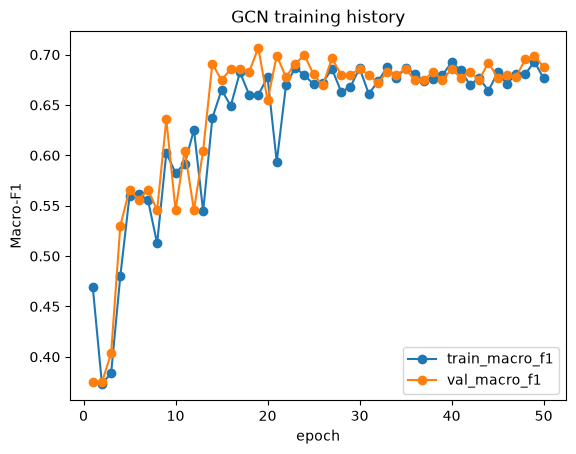

In [13]:
history_gcn, time_gcn = fit_model(gcn, train_loader, val_loader, epochs=50)
history_gcn.plot(x="epoch", y=["train_macro_f1", "val_macro_f1"], marker="o")
plt.ylabel("Macro-F1")
plt.title("GCN training history")
plt.show()

# Part IX — Pooling experiment


In [14]:
pooling_results = []
pooling_models = {}
for pooling in ["mean", "sum", "max"]:
    m = GCNClassifier(dataset.num_node_features, BASELINE_GCN_HIDDEN, dataset.num_classes, pooling=pooling).to(DEVICE)
    h, elapsed = fit_model(m, train_loader, val_loader, epochs=40)
    metrics = evaluate(m, val_loader)
    pooling_models[pooling] = m
    pooling_results.append({
        "pooling": pooling,
        "parameters": count_trainable_parameters(m),
        "macro_f1": metrics["macro_f1"],
        "accuracy": metrics["accuracy"],
        "seconds": elapsed
    })
pooling_results_df = pd.DataFrame(pooling_results).sort_values("macro_f1", ascending=False)
display(pooling_results_df)

001 | train F1=0.373 | val F1=0.375
010 | train F1=0.574 | val F1=0.591
020 | train F1=0.671 | val F1=0.683
030 | train F1=0.678 | val F1=0.696
040 | train F1=0.659 | val F1=0.699
001 | train F1=0.471 | val F1=0.609
010 | train F1=0.532 | val F1=0.632
020 | train F1=0.685 | val F1=0.568
030 | train F1=0.709 | val F1=0.663
040 | train F1=0.712 | val F1=0.698


C:\Users\user\Desktop\kse\practicals\kse-github\.venv\Lib\site-packages\torch_geometric\utils\_scatter.py:91: UserWarning: The usage of `scatter(reduce='max')` can be accelerated via the 'torch-scatter' package, but it was not found
  warnings.warn(


001 | train F1=0.424 | val F1=0.375


C:\Users\user\Desktop\kse\practicals\kse-github\.venv\Lib\site-packages\torch_geometric\utils\_scatter.py:91: UserWarning: The usage of `scatter(reduce='max')` can be accelerated via the 'torch-scatter' package, but it was not found
  warnings.warn(
C:\Users\user\Desktop\kse\practicals\kse-github\.venv\Lib\site-packages\torch_geometric\utils\_scatter.py:91: UserWarning: The usage of `scatter(reduce='max')` can be accelerated via the 'torch-scatter' package, but it was not found
  warnings.warn(
C:\Users\user\Desktop\kse\practicals\kse-github\.venv\Lib\site-packages\torch_geometric\utils\_scatter.py:91: UserWarning: The usage of `scatter(reduce='max')` can be accelerated via the 'torch-scatter' package, but it was not found
  warnings.warn(
C:\Users\user\Desktop\kse\practicals\kse-github\.venv\Lib\site-packages\torch_geometric\utils\_scatter.py:91: UserWarning: The usage of `scatter(reduce='max')` can be accelerated via the 'torch-scatter' package, but it was not found
  warnings.warn(


010 | train F1=0.581 | val F1=0.579


C:\Users\user\Desktop\kse\practicals\kse-github\.venv\Lib\site-packages\torch_geometric\utils\_scatter.py:91: UserWarning: The usage of `scatter(reduce='max')` can be accelerated via the 'torch-scatter' package, but it was not found
  warnings.warn(
C:\Users\user\Desktop\kse\practicals\kse-github\.venv\Lib\site-packages\torch_geometric\utils\_scatter.py:91: UserWarning: The usage of `scatter(reduce='max')` can be accelerated via the 'torch-scatter' package, but it was not found
  warnings.warn(
C:\Users\user\Desktop\kse\practicals\kse-github\.venv\Lib\site-packages\torch_geometric\utils\_scatter.py:91: UserWarning: The usage of `scatter(reduce='max')` can be accelerated via the 'torch-scatter' package, but it was not found
  warnings.warn(
C:\Users\user\Desktop\kse\practicals\kse-github\.venv\Lib\site-packages\torch_geometric\utils\_scatter.py:91: UserWarning: The usage of `scatter(reduce='max')` can be accelerated via the 'torch-scatter' package, but it was not found
  warnings.warn(


... (2 outputs left out)

030 | train F1=0.646 | val F1=0.734


C:\Users\user\Desktop\kse\practicals\kse-github\.venv\Lib\site-packages\torch_geometric\utils\_scatter.py:91: UserWarning: The usage of `scatter(reduce='max')` can be accelerated via the 'torch-scatter' package, but it was not found
  warnings.warn(
C:\Users\user\Desktop\kse\practicals\kse-github\.venv\Lib\site-packages\torch_geometric\utils\_scatter.py:91: UserWarning: The usage of `scatter(reduce='max')` can be accelerated via the 'torch-scatter' package, but it was not found
  warnings.warn(
C:\Users\user\Desktop\kse\practicals\kse-github\.venv\Lib\site-packages\torch_geometric\utils\_scatter.py:91: UserWarning: The usage of `scatter(reduce='max')` can be accelerated via the 'torch-scatter' package, but it was not found
  warnings.warn(
C:\Users\user\Desktop\kse\practicals\kse-github\.venv\Lib\site-packages\torch_geometric\utils\_scatter.py:91: UserWarning: The usage of `scatter(reduce='max')` can be accelerated via the 'torch-scatter' package, but it was not found
  warnings.warn(


040 | train F1=0.669 | val F1=0.738


,pooling,parameters,macro_f1,accuracy,seconds
2,max,17282,0.743472,0.760479,8.382438
1,sum,17282,0.724812,0.748503,8.095655
0,mean,17282,0.698603,0.724551,8.113789


# Part X — GIN

001 | train F1=0.486 | val F1=0.280
010 | train F1=0.563 | val F1=0.559
020 | train F1=0.680 | val F1=0.688
030 | train F1=0.680 | val F1=0.675
040 | train F1=0.720 | val F1=0.694
050 | train F1=0.724 | val F1=0.705


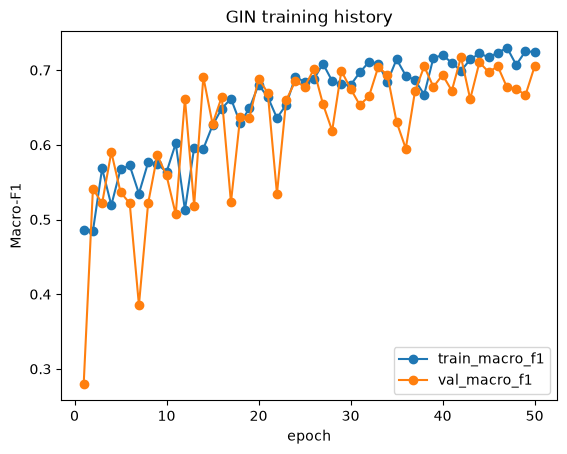

In [15]:
class GINClassifier(nn.Module):
    def __init__(self, in_dim, hidden_dim, n_classes, dropout=0.2):
        super().__init__()
        mlp1 = nn.Sequential(nn.Linear(in_dim,hidden_dim), nn.ReLU(), nn.Linear(hidden_dim,hidden_dim))
        mlp2 = nn.Sequential(nn.Linear(hidden_dim,hidden_dim), nn.ReLU(), nn.Linear(hidden_dim,hidden_dim))
        self.conv1 = GINConv(mlp1)
        self.conv2 = GINConv(mlp2)
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(hidden_dim,n_classes)

    def encode(self, x, edge_index, batch):
        x = F.relu(self.conv1(x,edge_index))
        x = F.relu(self.conv2(x,edge_index))
        return global_add_pool(x,batch)

    def forward(self, x, edge_index, batch):
        return self.classifier(self.dropout(self.encode(x,edge_index,batch)))

gin = GINClassifier(dataset.num_node_features, GIN_HIDDEN_DIM, dataset.num_classes).to(DEVICE)
history_gin, time_gin = fit_model(gin, train_loader, val_loader, epochs=50)
history_gin.plot(x="epoch", y=["train_macro_f1", "val_macro_f1"], marker="o")
plt.ylabel("Macro-F1")
plt.title("GIN training history")
plt.show()

Compare:

| Model | Pooling | Parameters | Val macro-F1 | Train time |
|---|---|---:|---:|---:|
| GCN | mean | | | |
| GCN | sum | | | |
| GIN | sum | | | |

# Part XI — GraphSAGE and GAT

GCN and GIN are not the only message-passing choices. Here we compare two additional layers:

- **GraphSAGE** aggregates a node's neighbourhood with a learned aggregation rule.
- **GAT** uses attention weights so different neighbours can contribute unequally.

For a node (v), a simplified GraphSAGE update is:

\[
h_v^{(l+1)} = \sigma\left(W^{(l)}[h_v^{(l)} \Vert \operatorname{AGG}({h_u^{(l)}:u\in\mathcal N(v)})]\right).
\]

GAT instead learns an attention coefficient (\alpha_{vu}) for each edge:

\[
h_v^{(l+1)} = \sigma\left(\sum_{u\in\mathcal N(v)} \alpha_{vu}W h_u^{(l)}\right).
\]

The implementations below use the same train/validation loaders and evaluation procedure as GCN and GIN.


In [16]:
class GraphSAGEClassifier(nn.Module):
    def __init__(self, in_dim, hidden_dim, n_classes, dropout=0.2):
        super().__init__()
        self.conv1 = SAGEConv(in_dim, hidden_dim)
        self.conv2 = SAGEConv(hidden_dim, hidden_dim)
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(hidden_dim, n_classes)

    def encode(self, x, edge_index, batch):
        x = F.relu(self.conv1(x, edge_index))
        x = F.relu(self.conv2(x, edge_index))
        return global_mean_pool(x, batch)

    def forward(self, x, edge_index, batch):
        z = self.dropout(self.encode(x, edge_index, batch))
        return self.classifier(z)


class GATClassifier(nn.Module):
    def __init__(self, in_dim, hidden_dim, n_classes, heads=4, dropout=0.2):
        super().__init__()
        # Concatenating four heads still gives hidden_dim output features.
        head_dim = hidden_dim // heads
        self.conv1 = GATConv(in_dim, head_dim, heads=heads, dropout=dropout)
        self.conv2 = GATConv(hidden_dim, head_dim, heads=heads, dropout=dropout)
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(hidden_dim, n_classes)

    def encode(self, x, edge_index, batch):
        x = F.elu(self.conv1(x, edge_index))
        x = F.elu(self.conv2(x, edge_index))
        return global_mean_pool(x, batch)

    def forward(self, x, edge_index, batch):
        z = self.dropout(self.encode(x, edge_index, batch))
        return self.classifier(z)


graphsage = GraphSAGEClassifier(
    dataset.num_node_features, BASELINE_GCN_HIDDEN, dataset.num_classes
).to(DEVICE)
gat = GATClassifier(
    dataset.num_node_features, BASELINE_GCN_HIDDEN, dataset.num_classes
).to(DEVICE)

history_graphsage, time_graphsage = fit_model(
    graphsage, train_loader, val_loader, epochs=50
)
history_gat, time_gat = fit_model(
    gat, train_loader, val_loader, epochs=50
)

message_passing_results = pd.DataFrame([
    {
        "model": "GraphSAGE",
        "parameters": count_trainable_parameters(graphsage),
        "best_val_macro_f1": history_graphsage["val_macro_f1"].max(),
        "train_time_s": time_graphsage,
    },
    {
        "model": "GAT",
        "parameters": count_trainable_parameters(gat),
        "best_val_macro_f1": history_gat["val_macro_f1"].max(),
        "train_time_s": time_gat,
    },
])
display(message_passing_results)


001 | train F1=0.450 | val F1=0.404
010 | train F1=0.633 | val F1=0.692
020 | train F1=0.667 | val F1=0.678
030 | train F1=0.690 | val F1=0.688
040 | train F1=0.683 | val F1=0.675
050 | train F1=0.667 | val F1=0.691
001 | train F1=0.391 | val F1=0.375
010 | train F1=0.581 | val F1=0.565
020 | train F1=0.563 | val F1=0.591
030 | train F1=0.642 | val F1=0.683
040 | train F1=0.700 | val F1=0.691
050 | train F1=0.693 | val F1=0.693


,model,parameters,best_val_macro_f1,train_time_s
0,GraphSAGE,34050,0.704472,8.822525
1,GAT,17794,0.700857,12.216993


# Part XII — Learned graph embeddings

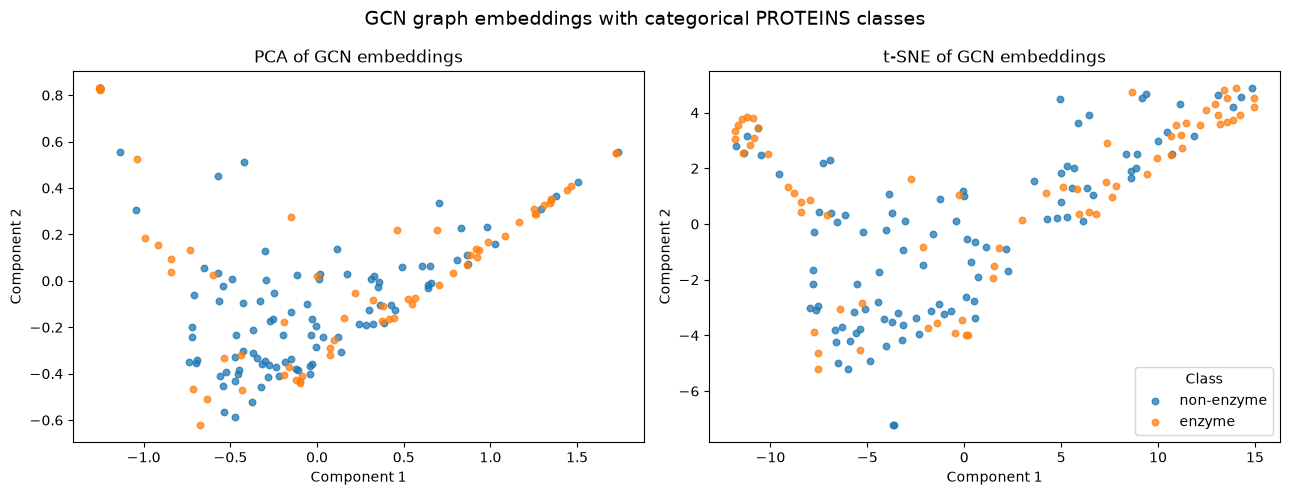

In [17]:
@torch.no_grad()
def extract_embeddings(model, loader):
    model.eval()
    Z, Y = [], []
    for batch in loader:
        batch = batch.to(DEVICE)
        z = model.encode(batch.x, batch.edge_index, batch.batch)
        Z.append(z.cpu().numpy())
        Y.append(batch.y.view(-1).cpu().numpy())
    return np.vstack(Z), np.concatenate(Y)

Z_test, y_test_embed = extract_embeddings(gcn, test_loader)
embedding_classes = pd.Categorical(
    [CLASS_NAMES[int(value)] for value in y_test_embed],
    categories=[CLASS_NAMES[int(value)] for value in sorted(np.unique(labels))]
)
class_codes = embedding_classes.codes

# PCA is a linear projection; t-SNE is a nonlinear neighborhood-preserving view.
Z_pca = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(Z_test)
Z_tsne = TSNE(
    n_components=2, perplexity=30, init="pca", learning_rate="auto",
    max_iter=750, random_state=RANDOM_STATE
).fit_transform(Z_test)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, coordinates, title in zip(axes, [Z_pca, Z_tsne], ["PCA of GCN embeddings", "t-SNE of GCN embeddings"]):
    for code, category in enumerate(embedding_classes.categories):
        mask = class_codes == code
        ax.scatter(coordinates[mask, 0], coordinates[mask, 1], s=22, alpha=0.75, label=category)
    ax.set_title(title)
    ax.set_xlabel("Component 1")
    ax.set_ylabel("Component 2")
axes[1].legend(title="Class")
fig.suptitle("GCN graph embeddings with categorical PROTEINS classes", fontsize=14)
plt.tight_layout()
plt.show()

# Part XIII — Transfer learning

A graph encoder learns:

\[
G \rightarrow z_G
\]

We can reuse this encoder on a related downstream task.

### Frozen transfer

\[
\text{pretrained encoder (frozen)} \rightarrow \text{new classifier}
\]

### Fine-tuning

\[
\text{pretrained encoder} + \text{new classifier} \rightarrow \text{joint update}
\]

## Auxiliary pretraining task

For a classroom demonstration, pretrain the encoder to classify whether a graph is **smaller or larger than the median graph size**.

\[
y_{aux} =
\mathbb{1}[N > median(N)]
\]

This is intentionally simple and **not an optimal biological pretraining objective**.

It demonstrates the mechanics of transfer learning and also gives us a useful methodological warning:

> if graph size correlates with the real class, pretraining may transfer a shortcut.

In [18]:
node_counts = np.array([g.num_nodes for g in dataset])
median_nodes = np.median(node_counts)
aux_labels = (node_counts > median_nodes).astype(int)

def clone_with_new_label(data, label):
    d = data.clone()
    d.y = torch.tensor([int(label)], dtype=torch.long)
    return d

pretrain_graphs = [clone_with_new_label(dataset[i], aux_labels[i]) for i in train_idx]

pre_idx, pv_idx = train_test_split(
    np.arange(len(pretrain_graphs)),
    test_size=0.20,
    stratify=[int(g.y.item()) for g in pretrain_graphs],
    random_state=RANDOM_STATE
)

pretrain_loader = DataLoader([pretrain_graphs[i] for i in pre_idx], batch_size=64, shuffle=True)
preval_loader = DataLoader([pretrain_graphs[i] for i in pv_idx], batch_size=128, shuffle=False)

# Part XIV — Pretrain the encoder

001 | train F1=0.391 | val F1=0.474
010 | train F1=0.530 | val F1=0.487
020 | train F1=0.602 | val F1=0.634
030 | train F1=0.586 | val F1=0.614


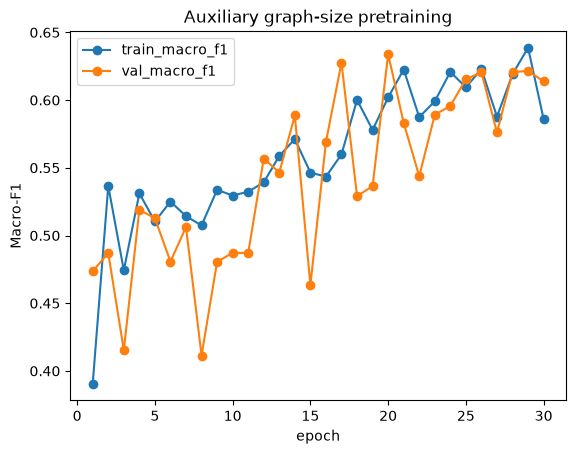

In [19]:
pretrain_model = GCNClassifier(
    dataset.num_node_features, BASELINE_GCN_HIDDEN, 2, pooling="mean"
).to(DEVICE)

pretrain_history, pretrain_time = fit_model(
    pretrain_model, pretrain_loader, preval_loader, epochs=30
)
pretrain_history.plot(x="epoch", y=["train_macro_f1", "val_macro_f1"], marker="o")
plt.ylabel("Macro-F1")
plt.title("Auxiliary graph-size pretraining")
plt.show()

pretrained_encoder_state = {
    "conv1": copy.deepcopy(pretrain_model.conv1.state_dict()),
    "conv2": copy.deepcopy(pretrain_model.conv2.state_dict())
}

# Part XV — Frozen transfer

In [20]:
def load_encoder(model, state):
    model.conv1.load_state_dict(state["conv1"])
    model.conv2.load_state_dict(state["conv2"])

def freeze_encoder(model):
    for p in model.conv1.parameters(): p.requires_grad = False
    for p in model.conv2.parameters(): p.requires_grad = False

def unfreeze_encoder(model):
    for p in model.conv1.parameters(): p.requires_grad = True
    for p in model.conv2.parameters(): p.requires_grad = True

frozen_transfer = GCNClassifier(
    dataset.num_node_features, BASELINE_GCN_HIDDEN, dataset.num_classes, pooling="mean"
).to(DEVICE)
load_encoder(frozen_transfer, pretrained_encoder_state)
freeze_encoder(frozen_transfer)
print("Trainable parameters:", count_trainable_parameters(frozen_transfer))
frozen_history, frozen_time = fit_model(
    frozen_transfer, train_loader, val_loader, epochs=30, lr=1e-3
)

Trainable parameters: 258
001 | train F1=0.455 | val F1=0.375
010 | train F1=0.441 | val F1=0.444
020 | train F1=0.554 | val F1=0.559
030 | train F1=0.578 | val F1=0.548


# Part XVI — Fine-tuned transfer

In [21]:
finetune_model = GCNClassifier(
    dataset.num_node_features, BASELINE_GCN_HIDDEN, dataset.num_classes, pooling="mean"
).to(DEVICE)
load_encoder(finetune_model, pretrained_encoder_state)
unfreeze_encoder(finetune_model)
finetune_history, finetune_time = fit_model(
    finetune_model, train_loader, val_loader, epochs=30, lr=3e-4
)

001 | train F1=0.455 | val F1=0.543
010 | train F1=0.373 | val F1=0.375
020 | train F1=0.548 | val F1=0.544
030 | train F1=0.615 | val F1=0.596


Compare:

| Model | Encoder initialization | Encoder trainable? | Val macro-F1 |
|---|---|---|---:|
| GCN scratch | random | yes | |
| Frozen transfer | pretrained | no | |
| Fine-tuned transfer | pretrained | yes | |

Questions:
- Did pretraining help?
- Did frozen transfer help or hurt?
- Did fine-tuning improve over frozen transfer?
- Was the auxiliary task actually aligned with the real task?

## More realistic graph pretraining

Better pretraining objectives could include:

- masked node-feature prediction;
- edge prediction;
- graph contrastive learning;
- subgraph prediction;
- pretraining on a larger related biological graph dataset.

This is a natural homework extension.

# Part XVII — Knowledge distillation

Transfer learning and distillation are different.

### Transfer learning
Reuse parameters/representations from another task.

### Distillation
Train a smaller **student** to imitate a stronger **teacher**.

\[
\text{teacher predictions} \rightarrow \text{student}
\]

001 | train F1=0.485 | val F1=0.375
010 | train F1=0.724 | val F1=0.676
020 | train F1=0.735 | val F1=0.680
030 | train F1=0.724 | val F1=0.698
040 | train F1=0.715 | val F1=0.731
050 | train F1=0.734 | val F1=0.699
060 | train F1=0.751 | val F1=0.706


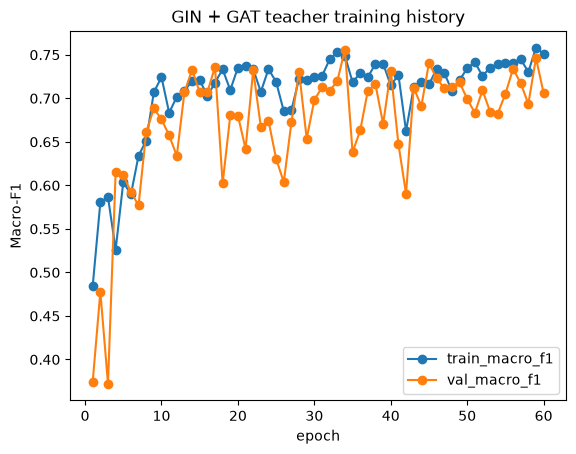

In [22]:
class LargerGINGATTeacher(nn.Module):
    def __init__(self, in_dim, hidden_dim, n_classes):
        super().__init__()
        self.convs = nn.ModuleList()
        dims = [in_dim, hidden_dim, hidden_dim, hidden_dim]

        for i in range(3):
            mlp = nn.Sequential(
                nn.Linear(dims[i], dims[i+1]),
                nn.ReLU(),
                nn.Linear(dims[i+1], dims[i+1])
            )
            self.convs.append(GINConv(mlp))

        # A multi-head GAT layer lets the teacher learn edge-specific attention
        # after the deeper GIN representation has been constructed.
        self.gat = GATConv(hidden_dim, hidden_dim // 4, heads=4, dropout=0.2)

        self.classifier = nn.Sequential(
            nn.Linear(hidden_dim,hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim,n_classes)
        )

    def encode(self, x, edge_index, batch):
        for conv in self.convs:
            x = F.relu(conv(x, edge_index))
        x = F.elu(self.gat(x, edge_index))
        return global_add_pool(x,batch)

    def forward(self, x, edge_index, batch):
        return self.classifier(self.encode(x,edge_index,batch))

teacher = LargerGINGATTeacher(dataset.num_node_features, TEACHER_GIN_HIDDEN, dataset.num_classes).to(DEVICE)
teacher_history, teacher_time = fit_model(teacher, train_loader, val_loader, epochs=60)
teacher_history.plot(x="epoch", y=["train_macro_f1", "val_macro_f1"], marker="o")
plt.ylabel("Macro-F1")
plt.title("GIN + GAT teacher training history")
plt.show()

## Distillation loss

\[
L =
\alpha L_{hard}
+
(1-\alpha)T^2
KL(p_T^{(T)} \Vert p_S^{(T)})
\]

In [23]:
def distillation_loss(student_logits, teacher_logits, targets, temperature=3.0, alpha=0.5):
    hard = F.cross_entropy(student_logits, targets)

    teacher_prob = F.softmax(teacher_logits / temperature, dim=1)
    student_log_prob = F.log_softmax(student_logits / temperature, dim=1)

    soft = F.kl_div(student_log_prob, teacher_prob, reduction="batchmean")

    return alpha*hard + (1-alpha)*(temperature**2)*soft

def train_distilled_epoch(student, teacher, loader, optimizer, temperature=3.0, alpha=0.5):
    student.train()
    teacher.eval()
    total_loss, y_true, y_pred = 0.0, [], []

    for batch in loader:
        batch = batch.to(DEVICE)
        optimizer.zero_grad()

        student_logits = student(batch.x,batch.edge_index,batch.batch)
        with torch.no_grad():
            teacher_logits = teacher(batch.x,batch.edge_index,batch.batch)

        loss = distillation_loss(
            student_logits, teacher_logits, batch.y.view(-1),
            temperature=temperature, alpha=alpha
        )
        loss.backward()
        optimizer.step()

        total_loss += loss.item()*batch.num_graphs
        y_true.extend(batch.y.view(-1).cpu().numpy())
        y_pred.extend(student_logits.argmax(1).detach().cpu().numpy())

    return {
        "loss": total_loss/len(loader.dataset),
        "accuracy": accuracy_score(y_true,y_pred),
        "macro_f1": f1_score(y_true,y_pred,average="macro")
    }

In [24]:
student = GCNClassifier(
    dataset.num_node_features, STUDENT_GCN_HIDDEN, dataset.num_classes, pooling="mean"
).to(DEVICE)

print("Student parameters:", count_trainable_parameters(student))

student_scratch = GCNClassifier(
    dataset.num_node_features, STUDENT_GCN_HIDDEN, dataset.num_classes, pooling="mean"
).to(DEVICE)
student_scratch_history, student_scratch_time = fit_model(
    student_scratch, train_loader, val_loader, epochs=40, lr=1e-3
)

student_optimizer = torch.optim.AdamW(student.parameters(), lr=1e-3, weight_decay=1e-5)
distilled_rows, best_state, best_val_f1 = [], None, -np.inf
distilled_start = time.time()
for epoch in range(1, 41):
    train_metrics = train_distilled_epoch(
        student, teacher, train_loader, student_optimizer, temperature=3.0, alpha=0.5)
    val_metrics = evaluate(student, val_loader)
    distilled_rows.append({
        "epoch": epoch,
        "train_macro_f1": train_metrics["macro_f1"],
        "val_macro_f1": val_metrics["macro_f1"],
        "train_loss": train_metrics["loss"],
        "val_loss": val_metrics["loss"],
    })
    if val_metrics["macro_f1"] > best_val_f1:
        best_val_f1 = val_metrics["macro_f1"]
        best_state = copy.deepcopy(student.state_dict())
student.load_state_dict(best_state)
student_distilled_time = time.time() - distilled_start
student_distilled_history = pd.DataFrame(distilled_rows)

distillation_results = pd.DataFrame([
    {"model": "GIN + GAT teacher", "parameters": count_trainable_parameters(teacher), **evaluate(teacher, val_loader)},
    {"model": "small GCN", "parameters": count_trainable_parameters(student_scratch), **evaluate(student_scratch, val_loader)},
    {"model": "distilled small GCN", "parameters": count_trainable_parameters(student), **evaluate(student, val_loader)},
]).drop(columns=["y_true", "y_pred"])
display(distillation_results)

Student parameters: 4546
001 | train F1=0.510 | val F1=0.375
010 | train F1=0.507 | val F1=0.533
020 | train F1=0.641 | val F1=0.686
030 | train F1=0.651 | val F1=0.685
040 | train F1=0.669 | val F1=0.675


,model,parameters,loss,accuracy,balanced_accuracy,macro_f1
0,GIN + GAT teacher,462594,0.587317,0.760479,0.763060,0.755848
1,small GCN,4546,0.614334,0.724551,0.691194,0.696220
2,distilled small GCN,4546,0.616224,0.730539,0.693731,0.699075


Suggested comparison:

| Model | Params | Training signal | Val macro-F1 |
|---|---:|---|---:|
| GIN + GAT teacher | | labels | |
| Small GCN | | labels | |
| Distilled small GCN | | labels + teacher | |

# Part XVIII — Final test evaluation

Selected using validation macro-F1: GIN + GAT teacher 0.7558479532163742
Final test metrics: {'loss': 0.5718988340771841, 'accuracy': 0.6946107784431138, 'balanced_accuracy': 0.7009803921568627, 'macro_f1': 0.6917815655194877}
              precision    recall  f1-score   support

           0      0.786     0.667     0.721        99
           1      0.602     0.735     0.662        68

    accuracy                          0.695       167
   macro avg      0.694     0.701     0.692       167
weighted avg      0.711     0.695     0.697       167



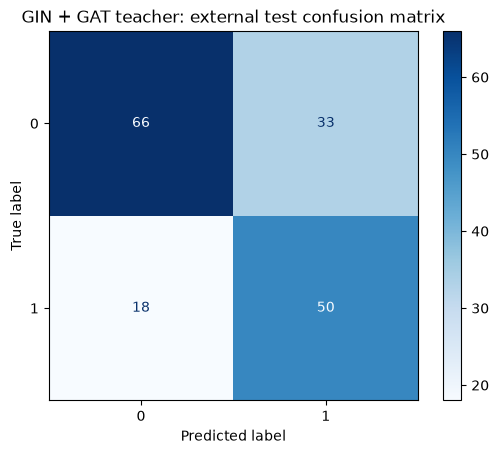

In [25]:
model_candidates = {
    "GCN": gcn,
    "GIN": gin,
    "GraphSAGE": graphsage,
    "GAT": gat,
    "Frozen-transfer GCN": frozen_transfer,
    "Fine-tuned GCN": finetune_model,
    "GIN + GAT teacher": teacher,
    "Small GCN": student_scratch,
    "Distilled small GCN": student,
}
validation_scores = {
    name: evaluate(model, val_loader)["macro_f1"]
    for name, model in model_candidates.items()
}
best_name = max(validation_scores, key=validation_scores.get)
best_model = model_candidates[best_name]
print("Selected using validation macro-F1:", best_name, validation_scores[best_name])

final_metrics = evaluate(best_model, test_loader)
print("Final test metrics:", {k: v for k, v in final_metrics.items() if not k.startswith("y_")})
print(classification_report(
    final_metrics["y_true"],
    final_metrics["y_pred"],
    digits=3
))
ConfusionMatrixDisplay.from_predictions(
    final_metrics["y_true"], final_metrics["y_pred"], cmap="Blues"
)
plt.title(f"{best_name}: external test confusion matrix")
plt.show()

# Final comparison

| Model | Representation | Transfer? | Distilled? | Params | Test macro-F1 |
|---|---|---|---|---:|---:|
| Logistic Regression | graph statistics | no | no | | |
| Random Forest | graph statistics | no | no | | |
| GCN | learned graph embedding | no | no | | |
| GIN | learned graph embedding | no | no | | |
| GraphSAGE | learned graph embedding | no | no | | |
| GAT | learned graph embedding | no | no | | |
| Frozen-transfer GCN | pretrained encoder | yes | no | | |
| Fine-tuned GCN | pretrained encoder | yes | no | | |
| Small GCN | learned graph embedding | no | no | | |
| Distilled small GCN | teacher-guided | no | yes | | |

# Interpretation questions

1. Did graph-statistics baselines perform surprisingly well?
2. Did the GCN learn beyond simple graph size/density?
3. Did GIN outperform GCN?
4. Which pooling strategy worked best?
5. Did graph embeddings separate the classes?
6. Did pretraining help?
7. Did frozen transfer and fine-tuning behave differently?
8. Could graph-size pretraining create shortcut representations?
9. Did distillation improve the small student?
10. Which model would you deploy under a strict compute budget?

# Homework — Transfer a PROTEINS encoder to ENZYMES

## Goal

Transfer a graph encoder learned on the **PROTEINS** task to the related **ENZYMES** graph-classification task. Compare three initialization/training strategies:

1. **From scratch:** initialize the ENZYMES model randomly and train all parameters.
2. **Frozen transfer:** copy the convolutional encoder learned on PROTEINS, freeze it, and train only a new ENZYMES classifier head.
3. **Fine-tuned transfer:** copy the PROTEINS encoder, initialize a new ENZYMES classifier head, and update the encoder and head jointly.

The default `ENZYMES` benchmark contains 600 graphs and six graph-level classes. It uses the same style of small protein graphs and compatible secondary-structure node features, but the output layer must change from two logits to six logits.

## Required workflow

### 1. Inspect and split ENZYMES

- Load `TUDataset(root="data/TUDataset", name="ENZYMES")`.
- Report the number of graphs, node features, classes, and class proportions.
- Inspect graph sizes and at least one graph's `x`, `edge_index`, and `y`.
- Create one reproducible stratified train/validation/test split.
- Use the same split for all three models.

### 2. Build the three models

Use the same GCN encoder width and pooling rule in all models. Only the classifier output dimension should change to `enzymes.num_classes`.

- **Scratch:** random encoder and random classifier.
- **Frozen:** load the PROTEINS encoder weights, set `requires_grad=False` for its convolution layers, and train the new six-class classifier.
- **Fine-tuned:** start from the same transferred weights but leave the convolution layers trainable.

Do not copy the PROTEINS classifier head: it produces two logits and is not compatible with the six-class ENZYMES target.

### 3. Compare fairly

Use the same optimizer family, batch sizes, epoch budget, random seed policy, and early-stopping rule for all three models. Report:

- validation and test accuracy;
- macro-precision, macro-recall, and macro-F1;
- number of total and trainable parameters;
- training curves;
- a six-class confusion matrix.

### 4. Discuss the result

Answer the following questions:

1. Did transfer improve over random initialization?
2. Did freezing the encoder work as well as fine-tuning it?
3. Which ENZYMES classes are confused most often?
4. Are the PROTEINS and ENZYMES tasks sufficiently related for transfer to be useful?
5. Could the result be explained by the small dataset size or by class imbalance?
6. What would change if the source and target node-feature dimensions were different?

## Suggested starting scaffold

```python
enzymes = TUDataset(root="data/TUDataset", name="ENZYMES")
assert enzymes.num_node_features == dataset.num_node_features

# Save the source encoder only; do not transfer the two-class head.
source_encoder_state = {
    "conv1": copy.deepcopy(gcn.conv1.state_dict()),
    "conv2": copy.deepcopy(gcn.conv2.state_dict()),
}
```


